# 실내 잡음 N을 dB SPL로 — 기존 녹음 (Step8d)

> 2026-10-28 · 기존 장치 녹음만 사용 · 눈금 K는 [spl_cal.ipynb](spl_cal.ipynb) 4절 · 커널: `Tools/.venv`
> **먼저 볼 곳: 맨 끝 [결론부](#결론부) (그림 1장).** 그 위 1 ~ 4절은 근거 요약과 숫자 출력이다.

**왜 하나:** 탐지거리 식 r = 10^((L₁ − N − T) ÷ 20)의 **N**(잡음)을 dB SPL로 읽은 값이 아직 없다 (예산 페이지는 N = 50 dB SPL 가정). 이미 있는 실내 녹음을 K로 바꿔 **참고값**을 낸다. 정식 N은 Step8d 계획대로 설치 후보지에서 잰다.

**바꾸는 식:** dB SPL = 보드 dBFS(사인 기준) + K. K(1 kHz) = ch1 94.46 · ch2 96.52 · ch3 97.30.

| 녹음 | 날짜 | 환경 | 쓰는 구간 | K가 맞나 |
|---|---|---|---|---|
| `cal_spl` 조용한 구간 | 10-27 | 보드 눈금 직전, T 측정 예정 자리 | 13.0 ~ 31.5 s | **맞음** (같은 녹음에서 K를 냄) |
| `quiet_10min` | 10-16 | 조용한 방 | 5 ~ 600 s | 모름 |
| `fan_10min` | 10-16 | 선풍기 | 0 ~ 455 s (선풍기 켜진 구간) | 모름 |
| `doa_bg` · `doa_bg2` | 10-18 | 에어컨 | 전체 (각 60 s) | 모름 |

**한계:** (1) 10-16·10-18 때 트리머가 지금과 같았는지 기록이 없다. (2) 10-16 하루에 마이크 전원 RC 필터·ch3 모듈 교체·HSE 전환이 있었고 녹음마다 어느 상태였는지 기록이 없다. (3) K는 1 kHz 값이고 250 Hz에서는 보드가 약 4 dB 덜 받는다 (spl_cal 5절) — 낮은 쪽이 큰 잡음은 실제보다 작게 나올 수 있다. (4) 휴대폰 소음계 절대 오차 ±2 dB 안팎 (`추정`).

In [1]:
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.signal import welch
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("Malgun Gothic", "AppleGothic", "NanumGothic") if f in _have), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
DUMPS = "../dumps/stream"
K = np.array([94.46, 96.52, 97.30])                     # spl_cal.ipynb 4절 (1 kHz, 세 번 평균)
BAND = (300, 3000)
REC = [("cal_spl", ["seg_000.wav"], 13.0, 31.5), ("quiet_10min", ["seg_000.wav"], 5, 600), ("fan_10min", ["seg_000.wav"], 0, 455),
       ("doa_bg", ["seg_000.wav", "seg_001.wav"], 0, None), ("doa_bg2", ["seg_000.wav"], 0, None)]
dbfs = lambda ms: 10 * np.log10(2 * ms + 1e-20)        # 사인 기준 (spl_cal과 같음)
def band_ms(seg, fs, lo, hi):
    win = np.hanning(len(seg)); X = np.fft.rfft(seg * win); f = np.fft.rfftfreq(len(seg), 1 / fs); m = (f >= lo) & (f < hi)
    return 2 * np.sum(np.abs(X[m]) ** 2) / (len(seg) * np.sum(win ** 2))      # 대역 안 평균제곱 (Parseval, Hann 보정)
X = {}
for name, files, a, b in REC:
    parts = []
    for fn in files:
        y, FS = sf.read(f"{DUMPS}/{name}/{fn}", dtype="float64"); parts.append(y - y.mean(0))
    X[name] = (parts, a, b)
print(f"샘플레이트 {FS} Hz; " + ", ".join(f"{n} {sum(len(p) for p in X[n][0]) / FS:.0f} s" for n in X))

샘플레이트 12500 Hz; cal_spl 177 s, quiet_10min 610 s, fan_10min 610 s, doa_bg 60 s, doa_bg2 60 s


# 근거

## 1. 한 창 손으로 따라가기 — `quiet_10min` 100 s, ch1

1 s 창에 Hann 창을 씌워 FFT → 300 ~ 3000 Hz 칸의 크기 제곱 합 = 대역 안 평균제곱 (Parseval) → 사인 기준 dBFS → K를 더한다.

▶ 예측 지점 (T1) — **AI의 예상(기록):** spl_cal 6절에서 10-27 자리 ch1 바닥은 32.0 dB SPL, T_precheck B3b에서 `quiet_10min` 전체 크기는 10-27보다 9.7 dB 컸다. 대역도 그만큼 크다고 보면 약 42 dB SPL (`추정` — 전체 차이 = 대역 차이 가정). 실제는 아래 출력. 틀린 이유는 4절과 결론부 발견.

In [2]:
y = X["quiet_10min"][0][0][int(100 * FS):int(101 * FS), 0]
ms_all = np.mean(y ** 2); ms_b = band_ms(y, FS, *BAND)
print(f"창 100 ~ 101 s, {len(y)} 샘플, ch1")
print(f"전체 평균제곱 {ms_all:.3e} → 10·log₁₀(2 × {ms_all:.3e}) = {dbfs(ms_all):.2f} dBFS")
print(f"300 ~ 3000 Hz 평균제곱 {ms_b:.3e} (전체의 {ms_b / ms_all * 100:.0f} %) → {dbfs(ms_b):.2f} dBFS")
print(f"dB SPL = {dbfs(ms_b):.2f} + K {K[0]:.2f} = {dbfs(ms_b) + K[0]:.2f} dB SPL (대역)")

창 100 ~ 101 s, 12500 샘플, ch1
전체 평균제곱 8.090e-06 → 10·log₁₀(2 × 8.090e-06) = -47.91 dBFS
300 ~ 3000 Hz 평균제곱 2.366e-07 (전체의 3 %) → -63.25 dBFS
dB SPL = -63.25 + K 94.46 = 31.21 dB SPL (대역)


## 2 ~ 3. 모든 1 s 창의 대역 크기 → 녹음별 중앙값·p90 (Step8d의 N 기록 방식)

1 s 창, 겹침 없음, 채널마다 대역 dB SPL을 낸다. p90 = 창의 90 %가 그 값 아래. 녹음 안에서 크기가 일정한지는 최소·최대로 본다. 같은 방의 세 마이크(7 cm 간격)는 같은 소리를 들으므로, K로 감도를 맞춘 뒤에도 남는 채널 차이는 그 채널 자체 잡음의 몫이다.

In [3]:
L = {}
for name, (parts, a, b) in X.items():
    rows = []; t_off = 0.0
    for p in parts:
        n = len(p) // FS
        for i in range(n):
            t = t_off + i
            if t < a or (b is not None and t + 1 > b): continue
            rows.append([t] + [dbfs(band_ms(p[i * FS:(i + 1) * FS, c], FS, *BAND)) + K[c] for c in range(3)])
        t_off += n
    L[name] = np.array(rows)
TAB = {n: (np.median(v[:, 1:], 0), np.percentile(v[:, 1:], 90, 0)) for n, v in L.items()}
print(f"{'녹음':12s} | {'창':>4s} | {'ch1 중앙':>8s} {'p90':>5s} {'최소~최대':>11s} | {'ch2 중앙':>8s} {'p90':>5s} | {'ch3 중앙':>8s} {'p90':>5s} | 채널 차 (ch2−ch1 · ch3−ch1)")
for n, v in L.items():
    med, p90 = TAB[n]
    print(f"{n:12s} | {len(v):4d} | {med[0]:8.1f} {p90[0]:5.1f} {v[:, 1].min():5.1f}~{v[:, 1].max():5.1f} | {med[1]:8.1f} {p90[1]:5.1f} | {med[2]:8.1f} {p90[2]:5.1f} | {med[1] - med[0]:+.1f} · {med[2] - med[0]:+.1f}")

녹음           |    창 |   ch1 중앙   p90       최소~최대 |   ch2 중앙   p90 |   ch3 중앙   p90 | 채널 차 (ch2−ch1 · ch3−ch1)
cal_spl      |   18 |     30.0  32.0  29.5~ 32.8 |     35.8  36.4 |     40.0  41.2 | +5.8 · +10.0
quiet_10min  |  595 |     31.4  31.9  30.9~ 51.2 |     36.3  36.7 |     38.6  39.1 | +5.0 · +7.2
fan_10min    |  455 |     61.0  61.3  56.5~ 61.5 |     73.6  73.9 |     65.2  65.4 | +12.6 · +4.2
doa_bg       |   59 |     41.0  41.5  40.1~ 41.7 |     42.1  42.5 |     43.5  43.9 | +1.1 · +2.6
doa_bg2      |   59 |     39.0  39.5  38.2~ 39.9 |     40.2  40.7 |     43.6  43.8 | +1.2 · +4.6


## 4. 주파수 구간별 크기 — 대역 안과 밖

Welch(4096점, Hann)로 ch1 스펙트럼을 내고 네 구간의 크기를 dBFS로 더한다. **K를 더하지 않는다** (1 kHz K를 대역 밖에 쓰지 않으려고). 1/3 옥타브 칸을 더한 대역 값으로 3절 값을 검산한다 (칸 경계가 달라 1 ~ 2 dB 차이는 정상).

In [4]:
REG = [("0 ~ 45 Hz", 0, 44.5), ("45 ~ 280 Hz", 44.5, 280), ("280 ~ 2800 Hz", 280, 2806), ("2800 ~ 6250 Hz", 2806, FS / 2 + 1)]
fc = 1000 * 2 ** (np.arange(-13, 8) / 3); lo3, hi3 = fc * 2 ** (-1 / 6), fc * 2 ** (1 / 6)
PS, RG, OCT = {}, {}, {}
for name, (parts, a, b) in X.items():
    f, P = welch(parts[0][int(a * FS):int(b * FS) if b else None, 0], FS, window="hann", nperseg=4096); df = f[1] - f[0]
    PS[name] = (f, P); RG[name] = [dbfs(np.sum(P[(f >= x0) & (f < x1)]) * df) for _, x0, x1 in REG]
    OCT[name] = np.array([np.sum(P[(f >= l) & (f < h)]) * df for l, h in zip(lo3, hi3)])
print(f"{'녹음':12s} | " + " | ".join(f"{r[0]:>14s}" for r in REG) + " | 전체 [dBFS]")
for n in X: print(f"{n:12s} | " + " | ".join(f"{v:14.1f}" for v in RG[n]) + f" | {dbfs(np.sum(PS[n][1]) * (PS[n][0][1] - PS[n][0][0])):6.1f}")
print("quiet_10min − cal_spl: " + ", ".join(f"{r[0]} {RG['quiet_10min'][i] - RG['cal_spl'][i]:+.1f} dB" for i, r in enumerate(REG)))
inb = (lo3 >= 280) & (hi3 <= 3600)
print("검산 (315 ~ 2500 Hz 1/3 옥타브 칸 합 + K, ch1):", {n: round(float(dbfs(OCT[n][inb].sum()) + K[0]), 1) for n in X}, "· 3절 중앙값:", {n: round(float(TAB[n][0][0]), 1) for n in X})

녹음           |      0 ~ 45 Hz |    45 ~ 280 Hz |  280 ~ 2800 Hz | 2800 ~ 6250 Hz | 전체 [dBFS]
cal_spl      |          -71.8 |          -60.8 |          -63.5 |          -63.0 |  -57.3
quiet_10min  |          -48.4 |          -58.8 |          -62.1 |          -63.4 |  -47.7
fan_10min    |          -57.9 |          -49.5 |          -33.6 |          -41.5 |  -32.9
doa_bg       |          -63.6 |          -55.2 |          -53.4 |          -61.9 |  -50.6
doa_bg2      |          -70.2 |          -55.7 |          -55.3 |          -63.5 |  -52.1
quiet_10min − cal_spl: 0 ~ 45 Hz +23.4 dB, 45 ~ 280 Hz +2.1 dB, 280 ~ 2800 Hz +1.3 dB, 2800 ~ 6250 Hz -0.4 dB
검산 (315 ~ 2500 Hz 1/3 옥타브 칸 합 + K, ch1): {'cal_spl': 31.8, 'quiet_10min': 33.0, 'fan_10min': 61.2, 'doa_bg': 41.3, 'doa_bg2': 39.3} · 3절 중앙값: {'cal_spl': 30.0, 'quiet_10min': 31.4, 'fan_10min': 61.0, 'doa_bg': 41.0, 'doa_bg2': 39.0}


<a id="결론부"></a>
# 결론부

## 그림 — 실내 N 참고값과 채널 차이 (결정: Step8d에 참고값 기록, 예산 페이지 캡슐 잡음 가정 수정)

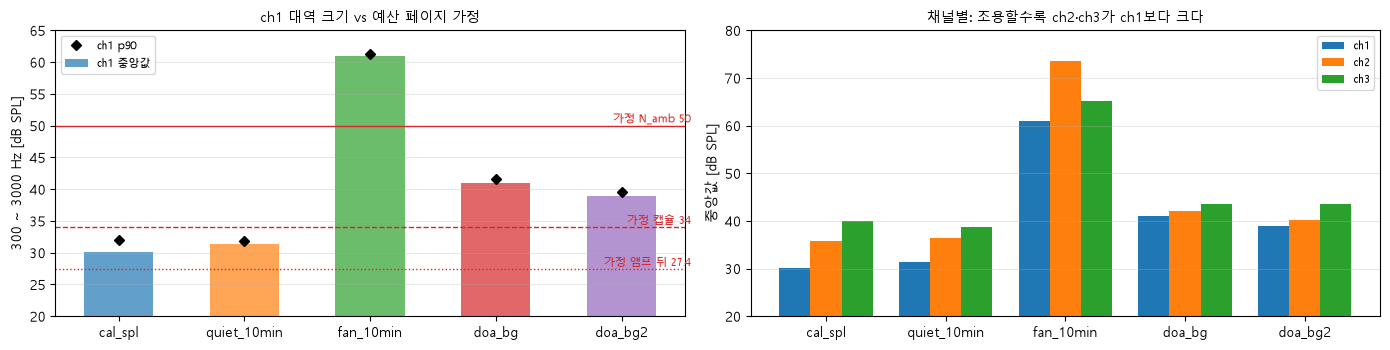

In [5]:
names = list(TAB); x = np.arange(len(names))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
ax[0].bar(x, [TAB[n][0][0] for n in names], 0.55, color=[f"C{j}" for j in range(len(names))], alpha=.7, label="ch1 중앙값")
ax[0].plot(x, [TAB[n][1][0] for n in names], "kD", ms=5, label="ch1 p90")
for v, s, ls in ((50, "가정 N_amb 50", "-"), (34, "가정 캡슐 34", "--"), (27.4, "가정 앰프 뒤 27.4", ":")):
    ax[0].axhline(v, color="C3", ls=ls, lw=1); ax[0].text(len(names) - 0.45, v + 0.5, s, fontsize=8, color="C3", ha="right")
ax[0].set_xticks(x); ax[0].set_xticklabels(names); ax[0].set_ylabel("300 ~ 3000 Hz [dB SPL]"); ax[0].set_ylim(20, 65)
ax[0].set_title("ch1 대역 크기 vs 예산 페이지 가정", fontsize=10); ax[0].grid(alpha=.3, axis="y"); ax[0].legend(fontsize=8, loc="upper left")
w = 0.26
for c in range(3): ax[1].bar(x + (c - 1) * w, [TAB[n][0][c] for n in names], w, label=f"ch{c + 1}")
ax[1].set_xticks(x); ax[1].set_xticklabels(names); ax[1].set_ylabel("중앙값 [dB SPL]"); ax[1].set_ylim(20, 80)
ax[1].set_title("채널별: 조용할수록 ch2·ch3가 ch1보다 크다", fontsize=10); ax[1].grid(alpha=.3, axis="y"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**볼 것:** 왼쪽 — 조용한 방 막대(cal_spl, quiet_10min)가 "가정 캡슐 34" 선보다 아래인지. 오른쪽 — 조용한 녹음에서 채널 차이가 크고, 에어컨에서는 작아지는지.

## 발견

In [6]:
for n in TAB: print(f"{n:12s}: ch1 중앙 {TAB[n][0][0]:.1f} · p90 {TAB[n][1][0]:.1f} dB SPL | 채널 차 {TAB[n][0][1] - TAB[n][0][0]:+.1f} · {TAB[n][0][2] - TAB[n][0][0]:+.1f}")
print("quiet_10min − cal_spl (구간별): " + ", ".join(f"{r[0]} {RG['quiet_10min'][i] - RG['cal_spl'][i]:+.1f} dB" for i, r in enumerate(REG)))

cal_spl     : ch1 중앙 30.0 · p90 32.0 dB SPL | 채널 차 +5.8 · +10.0
quiet_10min : ch1 중앙 31.4 · p90 31.9 dB SPL | 채널 차 +5.0 · +7.2
fan_10min   : ch1 중앙 61.0 · p90 61.3 dB SPL | 채널 차 +12.6 · +4.2
doa_bg      : ch1 중앙 41.0 · p90 41.5 dB SPL | 채널 차 +1.1 · +2.6
doa_bg2     : ch1 중앙 39.0 · p90 39.5 dB SPL | 채널 차 +1.2 · +4.6
quiet_10min − cal_spl (구간별): 0 ~ 45 Hz +23.4 dB, 45 ~ 280 Hz +2.1 dB, 280 ~ 2800 Hz +1.3 dB, 2800 ~ 6250 Hz -0.4 dB


- **1절 예상이 틀렸다** (예상 약 42, 실제 31.2 dB SPL). 10-16과 10-27 조용한 녹음의 전체 크기 차이는 거의 전부 **0 ~ 45 Hz**에서 생겼고, 대역 안 280 ~ 2800 Hz는 1.3 dB뿐이다 (4절). "전체 차이 = 대역 차이" 가정이 틀렸다.
- **두 조용한 녹음은 대역 안에서 1.3 ~ 1.4 dB, 2.8 kHz 위에서 0.4 dB 안으로 맞는다.** 트리머가 달랐다면 모든 주파수가 같이 움직였을 것이므로 트리머가 같았다는 쪽의 **정황**이다 (증거는 아님).
- **캡슐 잡음의 상한 (ch1):** 조용한 방 대역 크기 = 캡슐 + 보드 + 방 소리의 합 = 30.0 dB SPL (10-27). 그러므로 ch1 캡슐 잡음은 이 대역에서 30.0 dB SPL 이하다. ch2·ch3는 각자 크기가 더 커서 이 상한은 ch1에만 해당한다.
- **채널 차이:** 조용할 때 ch2 +5 ~ 6, ch3 +7 ~ 10 dB이고, 에어컨일 때 +1 ~ 5 dB로 줄어든다. 조용할 때 ch2·ch3 크기의 대부분은 그 채널 자체 잡음이라는 후보다. ch3는 10-16 모듈 교체 뒤에도 고역 잡음이 남았다는 기록(`Steps/logs/Step5.md`)과 같은 방향이다.
- 선풍기 녹음에서 ch2만 +12.6 dB인 이유는 가리지 않았다 (선풍기 위치 기록 없음).
- `cal_spl` 3절 중앙값 30.0과 spl_cal 6절의 32.0의 차이는 계산 방식이다 (6절은 18.5 s를 한 번에 평균, 3절은 1 s 창 중앙값). p90은 32.0으로 같다.

## 결론 후보 (사용자 확인 전)

| # | 후보 | 근거 | 아직 모르는 것 |
|---|---|---|---|
| 1 | Step8d에 "실내 N 참고값 (ch1, 300 ~ 3000 Hz)"으로 조용한 방 30 · 에어컨 39 ~ 41 · 선풍기 61 dB SPL을 기록 | 그림 왼쪽, 3절 | 10-16·10-18의 트리머·보드 상태, 300 Hz 근처 K. 설치 후보지(바깥) N은 여전히 없음 |
| 2 | 예산 페이지의 캡슐 잡음 가정 34 dB SPL을 ch1 실측 상한 30.0으로 바꾼다 | 그림 왼쪽, 발견 | 채널마다 다르다 (ch3 40.0). B0는 ch1만, 방향은 세 채널을 쓰므로 용도마다 쓸 값이 다르다 |
| 3 | 10-16 조용한 녹음의 0 ~ 45 Hz 성분(10-27보다 23 dB 큼)과 B0 저주파 오탐(T_precheck B1)의 관계를 따로 본다 | 4절 | 원인 (보드 상태 차이인지 방 소리인지) |